# DAT 262 — Capítulo 3: Procesos Markovianos aplicados a GitHub (GH Archive)

Proyecto: matriz de transición de tipos de evento + PageRank de repositorios, usando datos de una hora puntual de GH Archive.

**Autor:** Yeral — UMSA

## Celda 1 — Importar librerías

`requests`/`gzip`/`json` descargan y descomprimen el archivo de GH Archive. `numpy`/`pandas` arman y manipulan la tabla. `matplotlib` dibuja los gráficos. `networkx` construye la red de repositorios y calcula PageRank (ya trae la fórmula implementada).

In [1]:
# Si networkx no está instalado en tu entorno, descomenta la siguiente línea:
# !pip install networkx

import requests
import gzip
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

pd.set_option("display.max_colwidth", 60)


## Celda 2 — Descargar y cargar la hora elegida

Cambia `fecha` y `hora` si quieres analizar otro momento. Formato de fecha: `AAAA-MM-DD`, hora en UTC de 0 a 23.

In [2]:
fecha = "2026-03-10"   # martes, día laboral normal
hora = 12               # 12:00 UTC

url = f"https://data.gharchive.org/{fecha}-{hora}.json.gz"
print(f"Descargando: {url}")

respuesta = requests.get(url)
contenido = gzip.decompress(respuesta.content)
texto = contenido.decode("utf-8")

lineas = texto.strip().split("\n")
eventos = [json.loads(linea) for linea in lineas]

print(f"Eventos descargados: {len(eventos):,}")
print(f"Tamaño del archivo: {len(respuesta.content)/1024/1024:.2f} MB")


Descargando: https://data.gharchive.org/2026-03-10-12.json.gz
Eventos descargados: 161,817
Tamaño del archivo: 26.49 MB


## Celda 3 — Armar la tabla (DataFrame)

Extraemos solo las columnas que necesitamos (`type`, `created_at`, `actor_login`, `repo_name`) y ordenamos cronológicamente — esto es clave para la cadena de Markov, porque el orden en el tiempo define qué evento "sigue" a cuál.

In [3]:
df = pd.DataFrame({
    "id": [e.get("id") for e in eventos],
    "type": [e.get("type") for e in eventos],
    "created_at": pd.to_datetime([e.get("created_at") for e in eventos]),
    "actor_login": [e.get("actor", {}).get("login") for e in eventos],
    "repo_name": [e.get("repo", {}).get("name") for e in eventos],
})

df = df.sort_values("created_at").reset_index(drop=True)

print(df.shape)
df.head(10)


(161817, 5)


,id,type,created_at,actor_login,repo_name
0,7250135429,IssuesEvent,2026-03-10 12:00:00+00:00,DarrenPratt,DarrenPratt/MyGame
1,9232723120,PushEvent,2026-03-10 12:00:00+00:00,github-actions[bot],JeroenSwart/fco-waittime-scraper
2,9232723102,PushEvent,2026-03-10 12:00:00+00:00,github-actions[bot],neelniloy/lstv_backend
3,9232723087,PushEvent,2026-03-10 12:00:00+00:00,chchlin1018,chchlin1018/MeetingCoPilotAIApp1
4,9232723081,CreateEvent,2026-03-10 12:00:00+00:00,marriagestationpvtltd-lang,marriagestationpvtltd-lang/kapadastationnew
5,9232723067,PushEvent,2026-03-10 12:00:00+00:00,leon-99,leon-99/code-journal
6,9232723066,PushEvent,2026-03-10 12:00:00+00:00,RehanFazal77,RehanFazal77/nephio-my-ran
7,9232723062,PushEvent,2026-03-10 12:00:00+00:00,TFilipovic9,TFilipovic9/Osnove_Strojnog_Ucenja_LV
8,9232723051,PushEvent,2026-03-10 12:00:00+00:00,github-actions[bot],BerniceMalcolmjgc/xubianji
9,9232723046,PushEvent,2026-03-10 12:00:00+00:00,github-actions[bot],contatoleonardocdias-ctrl/monitoramento_barragens


## Celda 4 — Exploración general: usuarios, fechas, frecuencias

RESUMEN GENERAL DE LA HORA ANALIZADA
Fecha y hora:        2026-03-10 12:00 UTC
Total de eventos:    161,817
Usuarios únicos:     64,307
Repositorios únicos: 93,246
Tipos de evento:     16
Primer evento:       2026-03-10 12:00:00+00:00
Último evento:       2026-03-10 12:59:59+00:00

Top 15 usuarios más activos en esta hora:
actor_login
github-actions[bot]    28225
dependabot[bot]         1964
renovate[bot]           1241
pull[bot]               1122
Copilot                  993
harukayuka2              653
RehanFazal77             516
SoliSpirit               424
lovable-dev[bot]         411
vzhangbo                 376
mydatauploadtest         375
sidarthus89              374
kabirdjain               369
swa-runner-app[bot]      369
coderabbitai[bot]        343
Name: count, dtype: int64


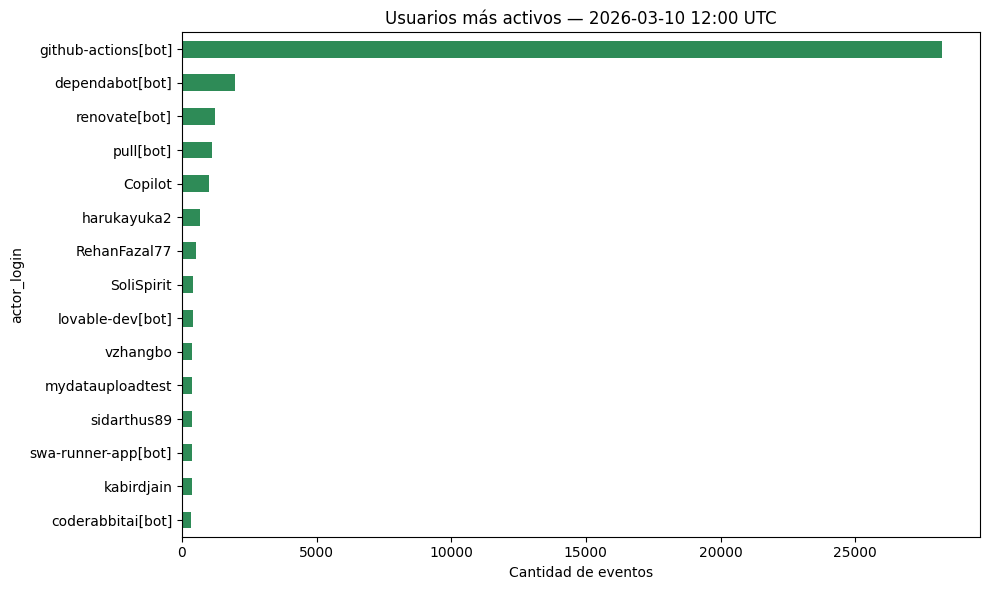


Cantidad por tipo de evento:
type
PushEvent                        129912
CreateEvent                       15103
DeleteEvent                        5675
PullRequestEvent                   3791
IssueCommentEvent                  1578
IssuesEvent                        1329
WatchEvent                         1308
PullRequestReviewCommentEvent      1224
PullRequestReviewEvent             1118
ReleaseEvent                        272
ForkEvent                           272
MemberEvent                         154
CommitCommentEvent                   30
PublicEvent                          22
GollumEvent                          21
DiscussionEvent                       8
Name: count, dtype: int64


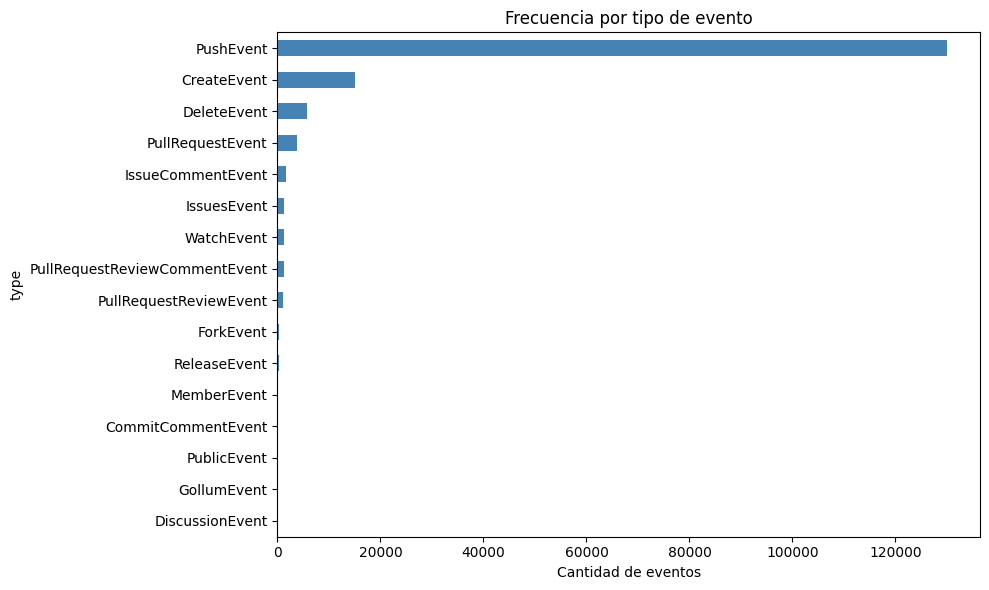

In [4]:
print("="*60)
print("RESUMEN GENERAL DE LA HORA ANALIZADA")
print("="*60)
print(f"Fecha y hora:        {fecha} {hora}:00 UTC")
print(f"Total de eventos:    {len(df):,}")
print(f"Usuarios únicos:     {df['actor_login'].nunique():,}")
print(f"Repositorios únicos: {df['repo_name'].nunique():,}")
print(f"Tipos de evento:     {df['type'].nunique()}")
print(f"Primer evento:       {df['created_at'].min()}")
print(f"Último evento:       {df['created_at'].max()}")

# --- Usuarios más frecuentes ---
top_usuarios = df["actor_login"].value_counts().head(15)
print("\nTop 15 usuarios más activos en esta hora:")
print(top_usuarios)

plt.figure(figsize=(10, 6))
top_usuarios.sort_values().plot(kind="barh", color="seagreen")
plt.xlabel("Cantidad de eventos")
plt.title(f"Usuarios más activos — {fecha} {hora}:00 UTC")
plt.tight_layout()
plt.show()

# --- Tipos de evento, cuántos de cada uno ---
conteo_tipos = df["type"].value_counts()
print("\nCantidad por tipo de evento:")
print(conteo_tipos)

plt.figure(figsize=(10, 6))
conteo_tipos.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Cantidad de eventos")
plt.title("Frecuencia por tipo de evento")
plt.tight_layout()
plt.show()


## Celda 5 — Frecuencia a través del tiempo (dentro de la hora)

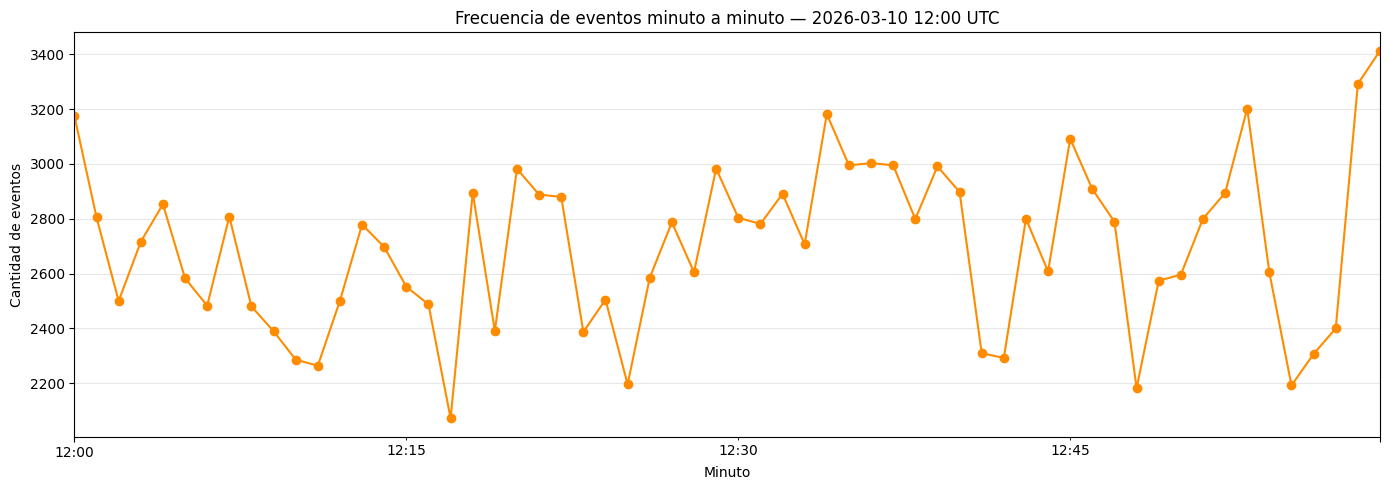

Promedio de eventos por minuto: 2696.9
Minuto más activo: 2026-03-10 12:59:00+00:00 (3413 eventos)


In [5]:
eventos_por_minuto = df.set_index("created_at").resample("1min").size()

plt.figure(figsize=(14, 5))
eventos_por_minuto.plot(kind="line", marker="o", color="darkorange")
plt.xlabel("Minuto")
plt.ylabel("Cantidad de eventos")
plt.title(f"Frecuencia de eventos minuto a minuto — {fecha} {hora}:00 UTC")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Promedio de eventos por minuto: {eventos_por_minuto.mean():.1f}")
print(f"Minuto más activo: {eventos_por_minuto.idxmax()} ({eventos_por_minuto.max()} eventos)")


## Celda 6 — Capítulo 3, Parte A: Cadena de Markov de tipos de evento

Armamos la matriz de transición $P$ entre tipos de evento y resolvemos la distribución estacionaria $\pi = \pi P$.

Matriz de transición P (fragmento):
                    CommitCommentEvent  CreateEvent  DeleteEvent  \
CommitCommentEvent                 0.0        0.000        0.000   
CreateEvent                        0.0        0.122        0.036   
DeleteEvent                        0.0        0.092        0.045   
DiscussionEvent                    0.0        0.125        0.000   
ForkEvent                          0.0        0.099        0.004   

                    DiscussionEvent  ForkEvent  
CommitCommentEvent              0.0      0.000  
CreateEvent                     0.0      0.001  
DeleteEvent                     0.0      0.001  
DiscussionEvent                 0.0      0.000  
ForkEvent                       0.0      0.040  

Distribución estacionaria (π) — a largo plazo, % de tiempo en cada estado:
PushEvent                        0.8028
CreateEvent                      0.0933
DeleteEvent                      0.0351
PullRequestEvent                 0.0234
IssueCommentEvent        

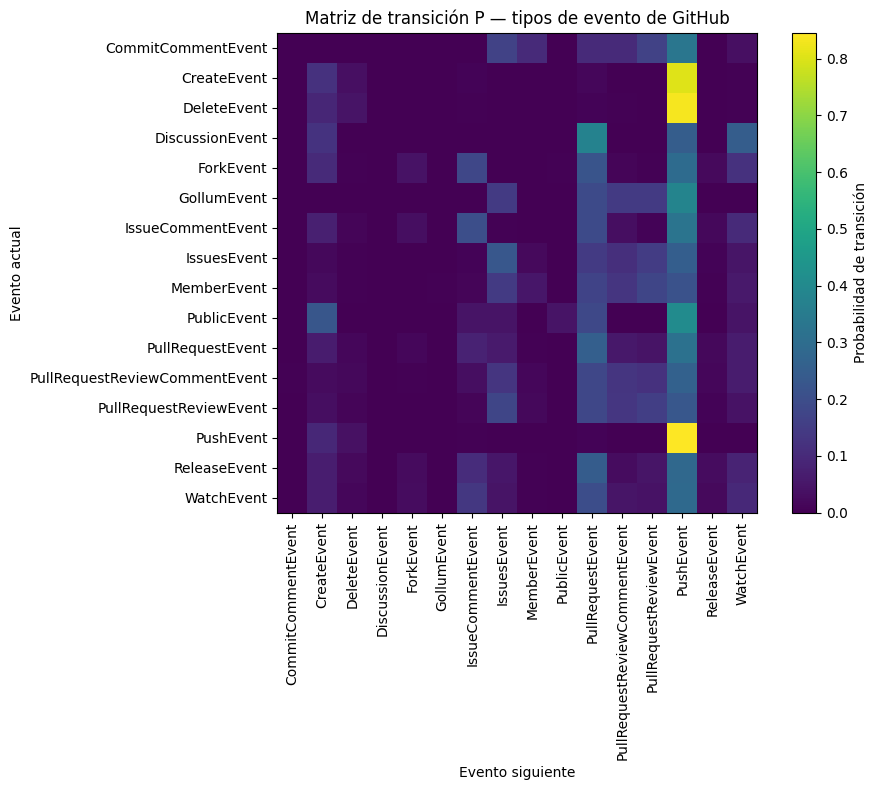

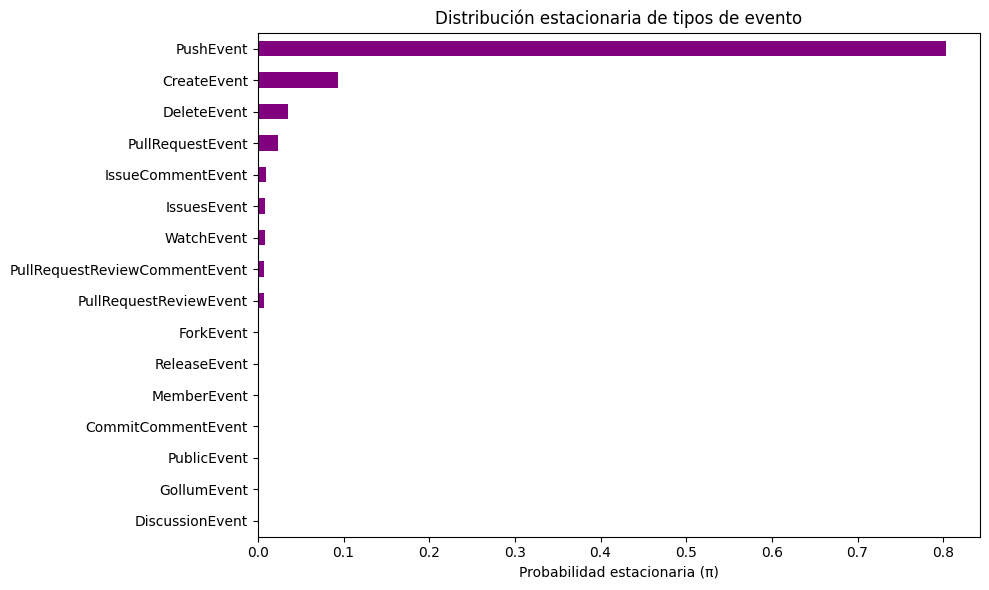

In [6]:
# 1. Armar la secuencia cronológica de tipos de evento
secuencia_tipos = df["type"].tolist()
tipos_unicos = sorted(df["type"].unique())
n = len(tipos_unicos)
indice = {t: i for i, t in enumerate(tipos_unicos)}

# 2. Contar las transiciones (de qué tipo a qué tipo se pasa)
M = np.zeros((n, n))
for actual, siguiente in zip(secuencia_tipos[:-1], secuencia_tipos[1:]):
    M[indice[actual], indice[siguiente]] += 1

# 3. Normalizar cada fila para que sume 1 (matriz de transición P)
sumas_fila = M.sum(axis=1, keepdims=True)
sumas_fila[sumas_fila == 0] = 1  # evita división por cero si algún estado no tuvo salidas
P = M / sumas_fila

print("Matriz de transición P (fragmento):")
print(pd.DataFrame(P, index=tipos_unicos, columns=tipos_unicos).round(3).iloc[:5, :5])

# 4. Calcular la distribución estacionaria: resolver pi = pi * P
eigvals, eigvecs = np.linalg.eig(P.T)
posicion = np.argmin(np.abs(eigvals - 1))  # buscamos el eigenvalor más cercano a 1
pi = np.real(eigvecs[:, posicion])
pi = pi / pi.sum()  # normalizar para que sume 1

distribucion_estacionaria = pd.Series(pi, index=tipos_unicos).sort_values(ascending=False)
print("\nDistribución estacionaria (π) — a largo plazo, % de tiempo en cada estado:")
print(distribucion_estacionaria.round(4))

# 5. Gráfico: mapa de calor de la matriz de transición
plt.figure(figsize=(10, 8))
plt.imshow(P, cmap="viridis")
plt.colorbar(label="Probabilidad de transición")
plt.xticks(range(n), tipos_unicos, rotation=90)
plt.yticks(range(n), tipos_unicos)
plt.xlabel("Evento siguiente")
plt.ylabel("Evento actual")
plt.title("Matriz de transición P — tipos de evento de GitHub")
plt.tight_layout()
plt.show()

# 6. Gráfico: distribución estacionaria
plt.figure(figsize=(10, 6))
distribucion_estacionaria.sort_values().plot(kind="barh", color="purple")
plt.xlabel("Probabilidad estacionaria (π)")
plt.title("Distribución estacionaria de tipos de evento")
plt.tight_layout()
plt.show()


**Interpretación:** la distribución estacionaria $\pi$ indica, si el sistema siguiera comportándose igual para siempre, qué porcentaje del tiempo el proceso "está" en cada tipo de evento — no es simplemente la frecuencia observada, es lo que predice el modelo de Markov a largo plazo. Si ambas coinciden mucho, es señal de que el proceso ya es bastante estable.

## Celda 7 — Capítulo 3, Parte B: PageRank de repositorios

Construimos un grafo dirigido: si un mismo usuario pasa del Repo A al Repo B, se crea una conexión A→B. Luego calculamos PageRank ($\alpha=0.85$, el valor clásico del formulario).

Nodos (repositorios) en la red: 36,281
Conexiones (aristas) en la red: 41,902

Top 15 repositorios más influyentes según PageRank:
aiandbotsgalore/copy-spaces-to-youtube-pipeline    0.002575
thedoggybrad/easylist-mirror                       0.001671
alire-project/alire-crates-ci                      0.001204
tscottjendev/MSDyn365BC.Sandbox.Code.History       0.001085
anton2423/didactic-broccoli                        0.000977
iREACH-UBC/CCAS_Dashboard                          0.000951
eyayq/eliv                                         0.000857
wenrey223/awas                                     0.000850
TopDataNBA1/nbapp                                  0.000795
sungqwe/studious-spork                             0.000794
0xlegionz/myPRoject                                0.000762
gaween/bookish                                     0.000715
nongakka/flixmono                                  0.000654
DawidSkinder/dawidskinder.pl-2026                  0.000636
actions-canary/ForkPRCanary  

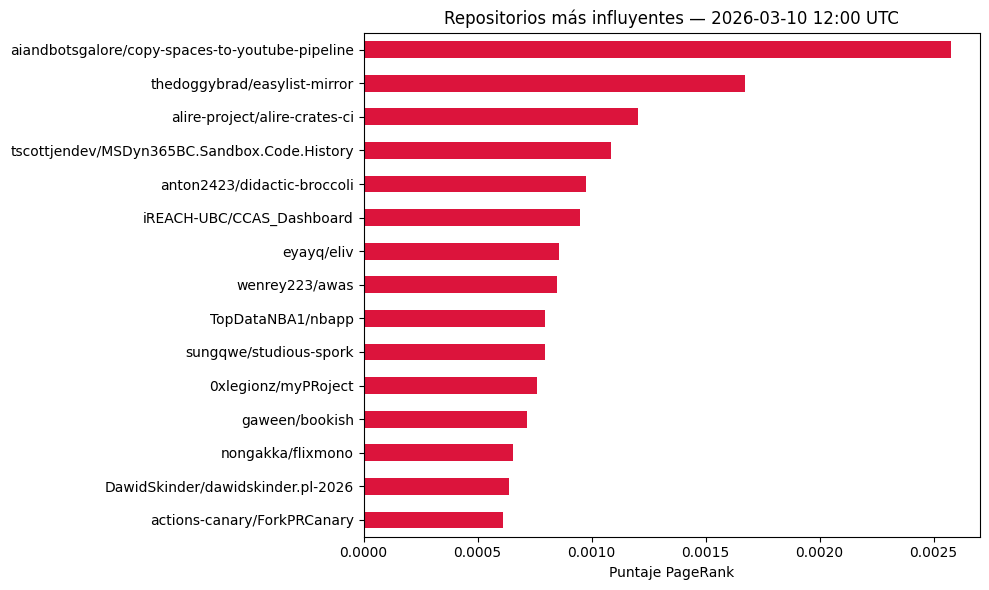

In [7]:
# 1. Armar un grafo dirigido: un "camino" de un usuario entre repos
#    cuenta como una conexión repo_A -> repo_B
G = nx.DiGraph()

for usuario, grupo in df.groupby("actor_login"):
    repos_del_usuario = grupo.sort_values("created_at")["repo_name"].tolist()
    # quitar repeticiones consecutivas (si hizo 3 push seguidos al mismo repo, cuenta como 1 "camino")
    repos_limpios = [r for i, r in enumerate(repos_del_usuario)
                      if i == 0 or r != repos_del_usuario[i - 1]]

    for repo_actual, repo_siguiente in zip(repos_limpios[:-1], repos_limpios[1:]):
        if G.has_edge(repo_actual, repo_siguiente):
            G[repo_actual][repo_siguiente]["weight"] += 1
        else:
            G.add_edge(repo_actual, repo_siguiente, weight=1)

print(f"Nodos (repositorios) en la red: {G.number_of_nodes():,}")
print(f"Conexiones (aristas) en la red: {G.number_of_edges():,}")

# 2. Calcular PageRank (alpha=0.85 es el valor clásico del formulario)
pagerank_scores = nx.pagerank(G, alpha=0.85, weight="weight")

top_repos = pd.Series(pagerank_scores).sort_values(ascending=False).head(15)
print("\nTop 15 repositorios más influyentes según PageRank:")
print(top_repos)

# 3. Gráfico de barras
plt.figure(figsize=(10, 6))
top_repos.sort_values().plot(kind="barh", color="crimson")
plt.xlabel("Puntaje PageRank")
plt.title(f"Repositorios más influyentes — {fecha} {hora}:00 UTC")
plt.tight_layout()
plt.show()


**Interpretación:** un repositorio con PageRank alto no es necesariamente el que tuvo más eventos — es el que está mejor conectado dentro de la red de usuarios activos, es decir, usuarios que también interactúan con otros repos importantes pasaron por ahí. Es la misma lógica que usa Google para ordenar páginas web.

---

### Resumen de lo que deja este notebook
1. Estadísticas generales (usuarios, repos, tipos, fechas)
2. Usuarios más activos y frecuencia por minuto
3. Matriz de transición $P$ y distribución estacionaria $\pi$ (Markov de tipos)
4. Red de repositorios y ranking PageRank (Markov aplicado a la red)

In [8]:
import requests

EVENTOS_MARKOV = 161_817   # eventos de la hora 12:00 UTC del 10-mar
cab = {"Accept-Encoding": "identity", "User-Agent": "DAT262-UMSA-proyecto"}

def tamano_hora(fecha, hora):
    url = f"https://data.gharchive.org/{fecha}-{hora}.json.gz"
    r = requests.head(url, headers=cab, timeout=30, allow_redirects=True)
    b = int(r.headers.get("Content-Length", 0))
    if b == 0:  # si el servidor no anuncia el tamaño, se mide descargando
        with requests.get(url, headers=cab, stream=True, timeout=(10, 120)) as g:
            b = sum(len(c) for c in g.raw.stream(1024 * 1024, decode_content=False))
    return b

print(f"{'hora':>5} | {'bytes':>12} | {'MiB (1024²)':>11} | {'MB (1000²)':>10}")
for h in range(10, 15):
    b = tamano_hora("2026-03-10", h)
    marca = "  <-- hora de Markov" if h == 12 else ""
    print(f"{h:>5} | {b:>12,} | {b/1024**2:>11.2f} | {b/1000**2:>10.2f}{marca}")

b12 = tamano_hora("2026-03-10", 12)
print(f"\nHora de Markov: {b12:,} bytes")
print(f"  = {b12/1024**2:.2f} MiB (base 1024)  |  {b12/1000**2:.2f} MB (base 1000)")
print(f"Bytes por evento (comprimido): {b12/EVENTOS_MARKOV:.0f}")

 hora |        bytes | MiB (1024²) | MB (1000²)
   10 |   31,856,703 |       30.38 |      31.86
   11 |   32,638,233 |       31.13 |      32.64
   12 |   27,781,082 |       26.49 |      27.78  <-- hora de Markov
   13 |   24,764,578 |       23.62 |      24.76
   14 |   24,428,648 |       23.30 |      24.43

Hora de Markov: 27,781,082 bytes
  = 26.49 MiB (base 1024)  |  27.78 MB (base 1000)
Bytes por evento (comprimido): 172


In [11]:
import json, os, shutil
os.makedirs("resultados_markov", exist_ok=True)
def guardar(nombre, obj):
    with open(f"resultados_markov/{nombre}.json", "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=1)

n_org = sum(1 for e in eventos if e.get("org"))
guardar("resumen", {
    "fecha": fecha, "hora_utc": hora, "total_eventos": int(len(df)),
    "usuarios_unicos": int(df["actor_login"].nunique()),
    "repositorios_unicos": int(df["repo_name"].nunique()),
    "tipos_evento": int(df["type"].nunique()),
    "primer_evento": str(df["created_at"].min()), "ultimo_evento": str(df["created_at"].max()),
    "eventos_con_organizacion": int(n_org), "eventos_cuenta_personal": int(len(eventos) - n_org),
    "grafo_nodos": int(G.number_of_nodes()), "grafo_aristas": int(G.number_of_edges()), "alpha_pagerank": 0.85})
guardar("frecuencia_tipos", {k: int(v) for k, v in conteo_tipos.items()})
guardar("usuarios_top15", {k: int(v) for k, v in top_usuarios.items()})
guardar("eventos_por_minuto", [{"minuto": str(t), "eventos": int(v)} for t, v in eventos_por_minuto.items()])
guardar("matriz_transicion", {"estados": tipos_unicos, "P": P.round(6).tolist(), "conteos": M.astype(int).tolist()})
guardar("distribucion_estacionaria", [{"tipo": t, "pi": float(p), "retorno_medio": (float(1/p) if p > 0 else None)}
                                      for t, p in distribucion_estacionaria.items()])
guardar("pagerank_top15", [{"repo": r, "pagerank": float(s)} for r, s in top_repos.items()])
top50 = set(pd.Series(pagerank_scores).sort_values(ascending=False).head(50).index)
guardar("red_top50", {"nodos": [{"id": r, "pagerank": float(pagerank_scores[r])} for r in top50],
                      "aristas": [{"source": a, "target": b, "peso": int(d["weight"])}
                                  for a, b, d in G.edges(data=True) if a in top50 and b in top50]})
shutil.make_archive("resultados_markov", "zip", ".", "resultados_markov")

'/content/resultados_markov.zip'

In [12]:
from google.colab import files
files.download("resultados_markov.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>